In [58]:
import numpy as np
import copy
import subprocess
from pathlib import Path
import matplotlib.pyplot as plt
import pickle
import os, shutil, tempfile
from concurrent.futures import ThreadPoolExecutor

In [59]:
# some const things
def relu(x):
	return np.maximum(x,0)

PARAMS = [
    "children_to_ctx",
    "W1", "b1",
    "W2", "b2",
    "W3"
]

KITES = os.path.abspath("./build/kites-cli")
PROG  = os.path.abspath("test.s")

In [60]:
# bring randomly generated instructions
def bring_shit(len_program=300, seed=0):
	if not seed:
		seed=np.random.randint(1200,2**31)
	result=subprocess.run(["./rand_gen4","test.s",str(seed),str(len_program)]
							,text=True,
							capture_output=True
						)
	print(result.stderr)
	result=subprocess.run(["./build/kites-cli","test.s","--reorder","2","--vm","rv5-h-nf"]
						,text=True,
						capture_output=True
						)

	# print(result.stderr)
	raw_data=np.fromfile("/tmp/ml/input_adj.bin",dtype=np.int32)
	num_instructions=int(raw_data[0])

	adjmatrix=raw_data[1:].reshape((num_instructions,num_instructions)).astype(np.float32) # weighted edges

	me=np.fromfile("/tmp/ml/input_me.bin",dtype=np.int32)
	data = me.reshape((num_instructions,4)).astype(np.float32) # rs1, rs2, rd, num_of_children without normalization
	#print(adjmatrix)
	
	rows = np.arange(num_instructions)

	# Extract columns and cast indices to integers
	r1 = data[:, 0].astype(int)
	r2 = data[:, 1].astype(int)
	r3 = data[:, 2].astype(int)
	val = data[:, 3]

	# 1. First 32 cols: Logical OR of one-hot(r1) and one-hot(r2)
	oh_r1_r2 = np.zeros((num_instructions, 32), dtype=np.float32)
	oh_r1_r2[rows, r1] = 1.0
	oh_r1_r2[rows, r2] = 1.0  # Setting 1.0 twice acts as a logical OR (even if r1 == r2)

	# 2. Next 32 cols: One-hot(r3)
	oh_r3 = np.zeros((num_instructions, 32), dtype=np.float32)
	oh_r3[rows, r3] = 1.0

	# 3. Final col (1 col): Softmax over all n values (numerically stable)
	exp_val = np.exp(val - np.max(val))
	softmax_val = (exp_val / np.sum(exp_val)).reshape(num_instructions, 1)

	# Combine into n x 65 matrix
	me_vector = np.hstack([oh_r1_r2, oh_r3, softmax_val])

	return adjmatrix, me_vector

In [61]:
# the goat model
# ctx=11, me = 32(registers hot) + 1(num_of_children normalized)

class Model:
	def __init__(self, ctx_dim=11, me_dim=65, hidden1=64, hidden2=28):
		self.id_dim = ctx_dim+me_dim
		self.me_dim = me_dim
		# initial matrix
		self.children_to_ctx = np.random.randn(ctx_dim, self.id_dim) * np.sqrt(2 / (self.id_dim))

		# mlp matrices
		self.W1 = np.random.randn(hidden1,self.id_dim) * np.sqrt(2 /self. id_dim)
		self.b1 = np.zeros(hidden1)

		self.W2 = np.random.randn(hidden2,hidden1) * np.sqrt(2 / hidden1)
		self.b2 = np.zeros(hidden2)

		self.W3 = np.random.randn(1,hidden2) * np.sqrt(2 / hidden2)

	def me_to_id_all(self, me, adj):
		n = len(me)
		ids = np.concatenate([me, np.zeros((n, self.id_dim-self.me_dim))], axis=1)
		for i in range(n - 1, -1, -1):
			w = adj[i]; mask = w > 0
			if mask.any():
				agg = (w[mask] @ ids[mask]) / w[mask].sum()      # edge-weighted mean
				ids[i, self.me_dim:] = np.tanh(self.children_to_ctx @ agg)
		return ids

	def priority_setter(self, instruction_id_array):
		priorities = relu(relu(instruction_id_array @ self.W1.T + self.b1) @ self.W2.T + self.b2) @ self.W3.T
		return priorities.astype(np.float64)
		

In [62]:

def eval_candidate(job):
    w, adj, me, wid = job
    wd = Path(tempfile.mkdtemp(prefix=f"es{wid}_"))  # private cwd
    (wd / "ml").mkdir()
    try:
        m = Model(); set_weights(m, w)
        m.priority_setter(m.me_to_id_all(me, adj)).tofile(wd / "ml" / "priority_out.bin")
        result=subprocess.run([KITES, PROG, "--compare-reorder", "3", "--vm", "rv5-h-nf",
                        "--cycles-original", "c1.txt", "--cycles-modified", "c2.txt"],
                       cwd=wd, text=True, capture_output=True, timeout=120)
        #print(result.stderr)
        c1 = int((wd / "c1.txt").read_text().split()[-1])
        c2 = int((wd / "c2.txt").read_text().split()[-1])
        return (c1 - c2) / c1
    finally:
        shutil.rmtree(wd, ignore_errors=True)

pool = ThreadPoolExecutor(max_workers=os.cpu_count()-2)   # create once, reuse every generation

In [63]:
# for a model returns an array of all weights
def get_weights(model):
    return np.concatenate([getattr(model, name).flatten() for name in PARAMS])

# given weight array, sets the weights
def set_weights(model, weights):
    start = 0

    for name in PARAMS:
        old = getattr(model, name)
        size = old.size

        new = weights[start:start + size].reshape(old.shape)
        setattr(model, name, new.copy())

        start += size

def es_step(model, me_vector, adjmatrix, N=64, sigma=0.07, alpha=0.02):
    w = get_weights(model)
    half = np.random.randn(N // 2, w.size)
    noise = np.concatenate([half, -half])
    # raw = np.empty(N)
    # for i in range(N):
    #     cand = copy.deepcopy(model); set_weights(cand, w + sigma * noise[i])
    #     raw[i] = reward_fn(cand, me_vector, adjmatrix)
    jobs = [(w + sigma * noise[i], adjmatrix, me_vector, i) for i in range(N)]
    raw = np.array(list(pool.map(eval_candidate, jobs))) # would calculate rewards
    
    ranks = np.empty(N); ranks[raw.argsort()] = np.arange(N)
    set_weights(model, w + alpha * ((ranks / (N - 1) - 0.5) @ noise) / (N * sigma))
    return raw.mean()  

In [77]:
CoRRL = Model()

In [ ]:
# restoring a previously trained model to train again
with open("Weights_50.pkl", "rb") as f:
	save_data = pickle.load(f)

CoRRL.children_to_ctx = save_data["children_to_ctx"].copy()
CoRRL.W1 = save_data["W1"].copy()
CoRRL.b1 = save_data["b1"].copy()
CoRRL.W2 = save_data["W2"].copy()
CoRRL.b2 = save_data["b2"].copy()
CoRRL.W3 = save_data["W3"].copy()


Done with 1/200 random generations. With current reward = 0.35483870967741943
Testing progress

Reward = 0.45374449339207046 for 1742041141

Reward = 0.463302752293578 for 1128699483

Done with 2/200 random generations. With current reward = 0.3125

Done with 3/200 random generations. With current reward = 0.42424242424242425

Done with 4/200 random generations. With current reward = 0.3333333333333333

Done with 5/200 random generations. With current reward = 0.3524305555555556

Done with 6/200 random generations. With current reward = 0.37626689189189194

Done with 7/200 random generations. With current reward = 0.39171511627906974

Done with 8/200 random generations. With current reward = 0.39609374999999997

Done with 9/200 random generations. With current reward = 0.23995535714285712

Done with 10/200 random generations. With current reward = 0.4090909090909091

Done with 11/200 random generations. With current reward = 0.3203125

Done with 12/200 random generations. With current

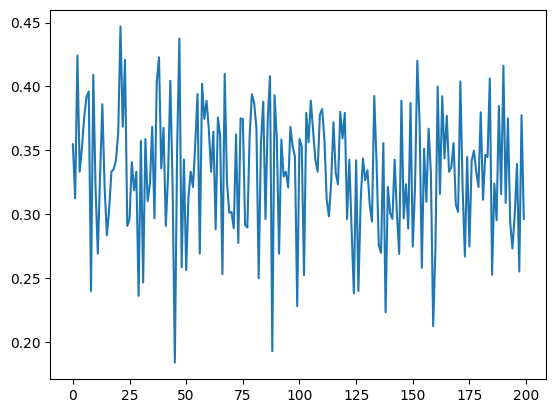

In [ ]:
# training
if __name__ == "__main__":
	rng = np.random.default_rng()
	seeds_vec = rng.integers(low=12141, high=2**31, size=2)

	all_rewards = []
	how_many_assem = 200
	for i in range(how_many_assem):
		lines = 50
		adjmatrix, me_vector = bring_shit(lines)

		# curr_reward = reward(CoRRL, me_vector, adjmatrix)
		
		curr_reward = es_step(CoRRL, me_vector=me_vector, adjmatrix=adjmatrix, N=64)
		all_rewards.append(curr_reward)

		print(f"Done with {i+1}/{how_many_assem} random generations. With current reward = {curr_reward}")


		if i%20 == 0:
			print("Testing progress")
			for seed in seeds_vec:
				adjmatrix, me_vector = bring_shit(100, int(seed))
				curr_reward = eval_candidate((get_weights(CoRRL), adjmatrix, me_vector, 0))
				print(f"Reward = {curr_reward} for {seed}")


	plt.plot(all_rewards)
	plt.show()


0.33307237808529666


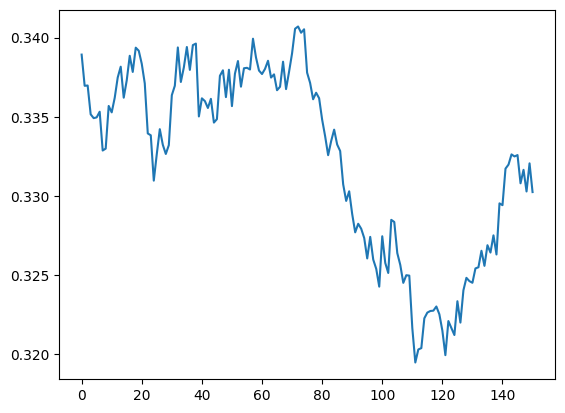

In [80]:
data= np.array(all_rewards)
print(np.mean(data))
window_size = 50

weights = np.ones(window_size) / window_size
moving_avg = np.convolve(data, weights, mode='valid')
plt.plot(moving_avg)
plt.show()

In [ ]:
# saving all the brains -- saves the whole BrainBatch as a dict of arrays
save_data = {
	"children_to_ctx": CoRRL.children_to_ctx, "W1": CoRRL.W1, "b1": CoRRL.b1, "W2": CoRRL.W2, "b2": CoRRL.b2, "W3": CoRRL.W3
}
with open("./src/reorder/Weights_5.pkl", "wb") as f:
	pickle.dump(save_data, f)
with open("Weights_50.pkl", "wb") as f:
	pickle.dump(save_data, f)